In [ ]:
"""
BCSE331P - Assessment 7: 1D, 2D and ND Analysis (Python)
NAME: P BALAJI SUBRAMANIAN
REG NO: 23BDS0271
"""

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
CSV_PATH = "orange_juice_withmissing.csv"

In [2]:
# 1. Load + light cleaning
df = pd.read_csv(CSV_PATH)
num_all = df.select_dtypes(include=np.number).columns
df[num_all] = df[num_all].fillna(df[num_all].median())
df = df.drop_duplicates().reset_index(drop=True)
for c in ["StoreID", "STORE", "SpecialCH", "SpecialMM"]:
    df[c] = df[c].astype(int).astype(str)

In [3]:
# e1071-style skewness / kurtosis (type 3 = e1071 default; kurtosis is EXCESS kurtosis)
def skewness(x):
    x = np.asarray(x, float); n = len(x)
    m2 = np.mean((x - x.mean()) ** 2); m3 = np.mean((x - x.mean()) ** 3)
    return (m3 / m2 ** 1.5) * ((n - 1) / n) ** 1.5


def kurtosis(x):
    x = np.asarray(x, float); n = len(x)
    m2 = np.mean((x - x.mean()) ** 2); m4 = np.mean((x - x.mean()) ** 4)
    return (m4 / m2 ** 2 - 3) * ((n - 1) / n) ** 2

In [4]:
# 2-3. Summary statistics stored in a data.frame
cols = ["PriceCH", "PriceMM", "LoyalCH", "SalePriceMM", "SalePriceCH", "PriceDiff"]
rows = {}
for c in cols:
    x = df[c]
    rows[c] = {
        "Mean": x.mean(), "Median": x.median(), "Min": x.min(), "Max": x.max(),
        "Range": x.max() - x.min(), "Variance": x.var(), "SD": x.std(),
        "IQR": x.quantile(.75) - x.quantile(.25),
        "Skewness": skewness(x), "Kurtosis": kurtosis(x),
    }
stats_df = pd.DataFrame(rows).T.round(4)
print("3. Summary statistics:\n", stats_df, "\n")

3. Summary statistics:
                Mean  Median   Min     Max   Range  Variance      SD     IQR  \
PriceCH      1.8676    1.86  1.69  2.0900  0.4000    0.0104  0.1021  0.2000   
PriceMM      2.0849    2.09  1.69  2.2900  0.6000    0.0179  0.1338  0.1900   
LoyalCH      0.5658    0.60  0.00  0.9999  0.9999    0.0956  0.3091  0.5327   
SalePriceMM  1.9647    2.09  1.19  2.2900  1.1000    0.0623  0.2497  0.4400   
SalePriceCH  1.8166    1.86  1.39  2.0900  0.7000    0.0201  0.1419  0.1400   
PriceDiff    0.1475    0.23 -0.67  0.6400  1.3100    0.0728  0.2698  0.3200   

             Skewness  Kurtosis  
PriceCH        0.0666   -0.7737  
PriceMM       -1.4599    2.1873  
LoyalCH       -0.2778   -1.0768  
SalePriceMM   -0.8153   -0.4787  
SalePriceCH   -0.9527    1.0013  
PriceDiff     -0.7644    0.4697   



4. Frequency table:
        Freq  RelFreq
STORE               
0       343   0.3282
1       154   0.1474
2       221   0.2115
3       190   0.1818
4       137   0.1311 



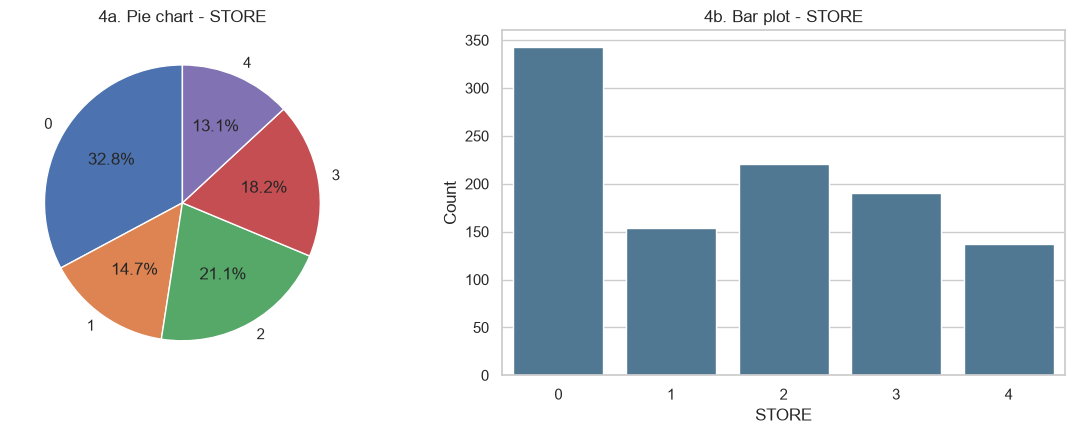

In [5]:
# 4. Frequency / relative frequency, pie chart and bar plot (categorical)
freq = df["STORE"].value_counts().sort_index()
rel = (freq / freq.sum()).round(4)
print("4. Frequency table:\n", pd.DataFrame({"Freq": freq, "RelFreq": rel}), "\n")
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].pie(freq.values, labels=freq.index, autopct="%1.1f%%", startangle=90)
ax[0].set_title("4a. Pie chart - STORE")
sns.barplot(x=freq.index, y=freq.values, ax=ax[1], color="#457b9d")
ax[1].set_title("4b. Bar plot - STORE"); ax[1].set_xlabel("STORE"); ax[1].set_ylabel("Count")
plt.tight_layout(); plt.show()

5. Binned frequency table (SalePriceMM):
 SalePriceMM
(1.189, 1.328]      6
(1.328, 1.465]     28
(1.465, 1.602]    116
(1.602, 1.74]     124
(1.74, 1.878]      56
(1.878, 2.015]    109
(2.015, 2.152]    351
(2.152, 2.29]     255
Name: count, dtype: int64 



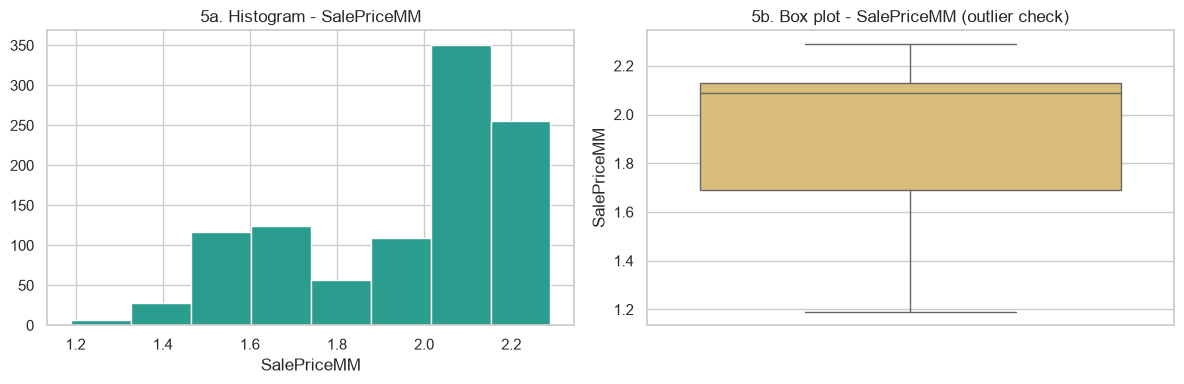

In [6]:
# 5. Binned frequency table, histogram and box plot (numerical)
bins = pd.cut(df["SalePriceMM"], bins=8)
print("5. Binned frequency table (SalePriceMM):\n", bins.value_counts().sort_index(), "\n")
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(df["SalePriceMM"], bins=8, color="#2a9d8f", edgecolor="white")
ax[0].set_title("5a. Histogram - SalePriceMM"); ax[0].set_xlabel("SalePriceMM")
sns.boxplot(y=df["SalePriceMM"], ax=ax[1], color="#e9c46a")
ax[1].set_title("5b. Box plot - SalePriceMM (outlier check)")
plt.tight_layout(); plt.show()

In [7]:
# 6. Contingency table + row/column percentages (prop.table)
ct = pd.crosstab(df["Store7"], df["Purchase"])
print("6. Contingency table:\n", ct, "\n")
print("   Row percentages:\n", (ct.div(ct.sum(axis=1), axis=0) * 100).round(2), "\n")
print("   Column percentages:\n", (ct.div(ct.sum(axis=0), axis=1) * 100).round(2), "\n")

6. Contingency table:
 Purchase   CH   MM
Store7            
No        375  327
Yes       264   79 

   Row percentages:
 Purchase     CH     MM
Store7                
No        53.42  46.58
Yes       76.97  23.03 

   Column percentages:
 Purchase     CH     MM
Store7                
No        58.69  80.54
Yes       41.31  19.46 



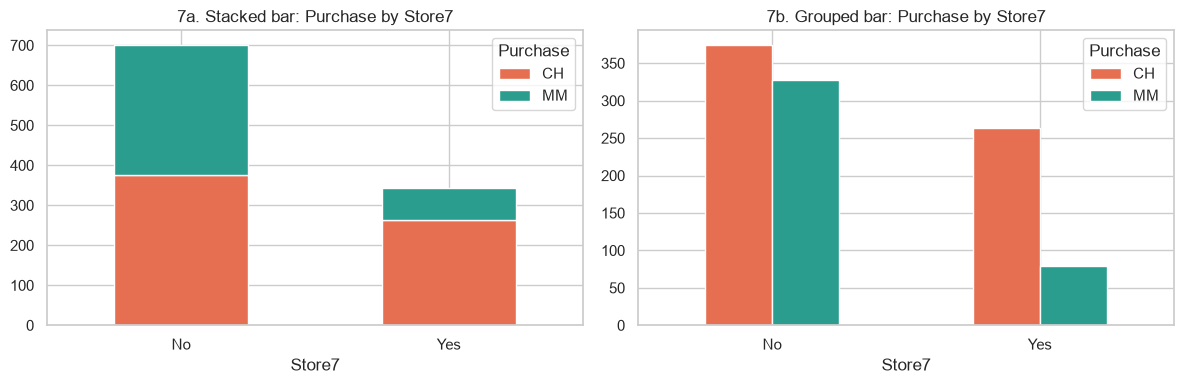

In [8]:
# 7. Stacked and grouped bar plots
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ct.plot(kind="bar", stacked=True, ax=ax[0], color=["#e76f51", "#2a9d8f"])
ax[0].set_title("7a. Stacked bar: Purchase by Store7"); ax[0].tick_params(axis="x", rotation=0)
ct.plot(kind="bar", ax=ax[1], color=["#e76f51", "#2a9d8f"])
ax[1].set_title("7b. Grouped bar: Purchase by Store7"); ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

In [9]:
# 8. Group statistics (aggregate)
agg = df.groupby("Purchase")["LoyalCH"].agg(["mean", "median", "std"]).round(4)
print("8. LoyalCH by Purchase:\n", agg, "\n")

8. LoyalCH by Purchase:
             mean  median     std
Purchase                        
CH        0.7239   0.778  0.2317
MM        0.3170   0.320  0.2455 



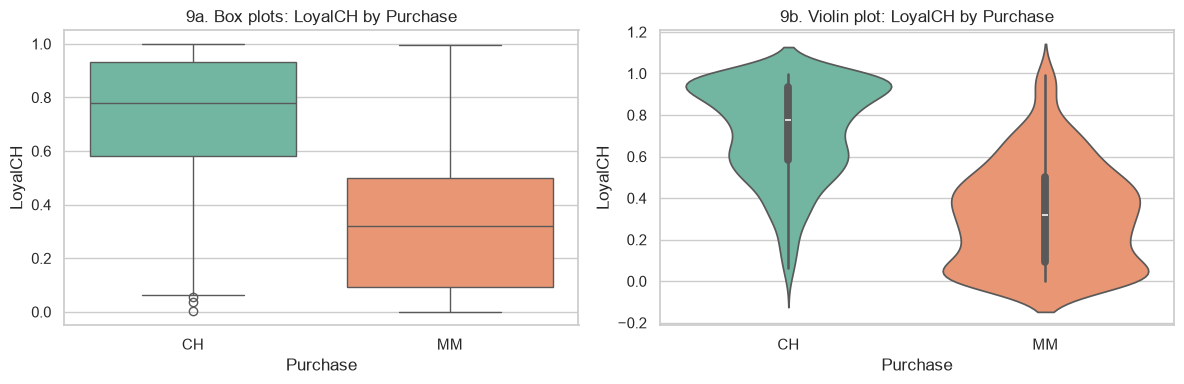

In [10]:
# 9. Side-by-side box plots and violin plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="Purchase", y="LoyalCH", ax=ax[0], hue="Purchase", palette="Set2", legend=False)
ax[0].set_title("9a. Box plots: LoyalCH by Purchase")
sns.violinplot(data=df, x="Purchase", y="LoyalCH", ax=ax[1], hue="Purchase", palette="Set2", legend=False)
ax[1].set_title("9b. Violin plot: LoyalCH by Purchase")
plt.tight_layout(); plt.show()

10. Pearson r = 0.5338, Spearman rho = 0.6937



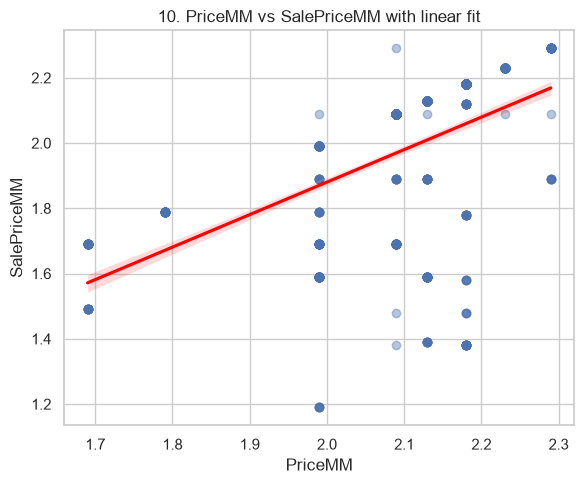

In [11]:
# 10. Pearson / Spearman + scatter with regression line
x, y = df["PriceMM"], df["SalePriceMM"]
print(f"10. Pearson r = {x.corr(y, method='pearson'):.4f}, "
      f"Spearman rho = {x.corr(y, method='spearman'):.4f}\n")
plt.figure(figsize=(6, 5))
sns.regplot(x=x, y=y, scatter_kws={"alpha": 0.4}, line_kws={"color": "red"})
plt.title("10. PriceMM vs SalePriceMM with linear fit")
plt.tight_layout(); plt.show()

11. Mean / SD of SalePriceMM by Store7 x Purchase:
                    mean     std
Store7 Purchase                
No     CH        2.0226  0.2178
       MM        1.9140  0.2746
Yes    CH        1.9823  0.2340
       MM        1.8408  0.2520 



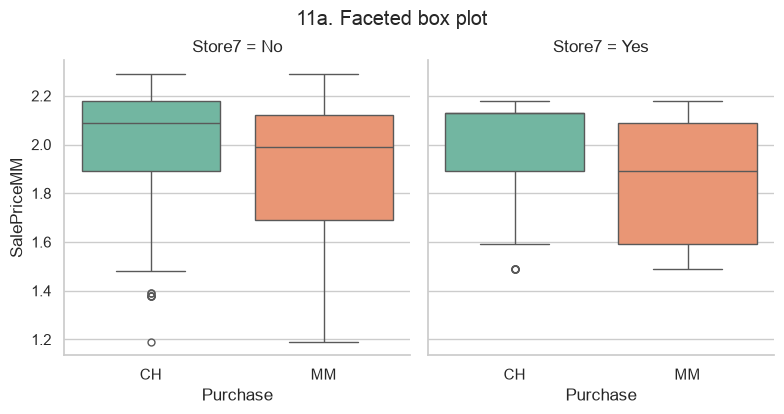

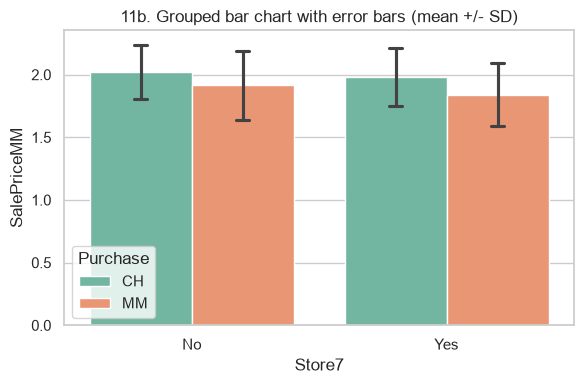

In [12]:
# 11. Two categoricals + one numeric
summ = df.groupby(["Store7", "Purchase"])["SalePriceMM"].agg(["mean", "std"]).round(4)
print("11. Mean / SD of SalePriceMM by Store7 x Purchase:\n", summ, "\n")
g = sns.catplot(data=df, x="Purchase", y="SalePriceMM", col="Store7", kind="box",
                hue="Purchase", palette="Set2", height=4, legend=False)
g.fig.suptitle("11a. Faceted box plot", y=1.03)
plt.show()
s = summ.reset_index()
plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Store7", y="SalePriceMM", hue="Purchase", errorbar="sd", capsize=0.1, palette="Set2")
plt.title("11b. Grouped bar chart with error bars (mean +/- SD)")
plt.tight_layout(); plt.show()

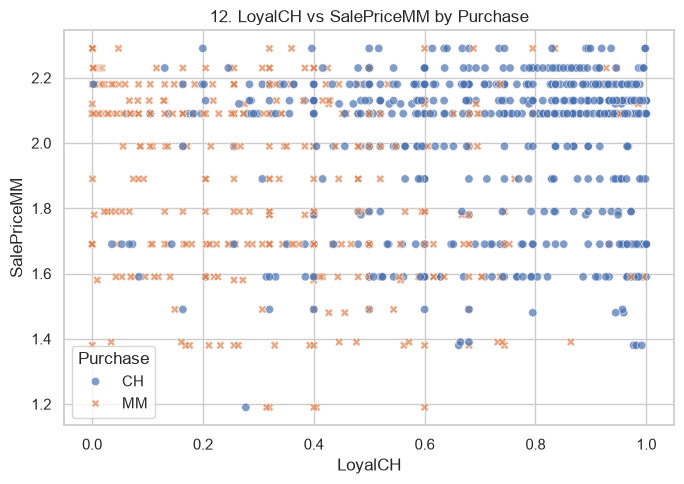

12. Correlation matrix for Purchase = CH:
              LoyalCH  SalePriceMM
LoyalCH       1.0000       0.0441
SalePriceMM   0.0441       1.0000 

12. Correlation matrix for Purchase = MM:
              LoyalCH  SalePriceMM
LoyalCH       1.0000      -0.2208
SalePriceMM  -0.2208       1.0000 



In [13]:
# 12. One categorical + two numerical
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="LoyalCH", y="SalePriceMM", hue="Purchase", style="Purchase", alpha=0.7)
plt.title("12. LoyalCH vs SalePriceMM by Purchase")
plt.tight_layout(); plt.show()
for lvl, grp in df.groupby("Purchase"):
    print(f"12. Correlation matrix for Purchase = {lvl}:\n",
          grp[["LoyalCH", "SalePriceMM"]].corr().round(4), "\n")

13. Correlation matrix:
              PriceCH  PriceMM  LoyalCH  SalePriceMM  SalePriceCH  PriceDiff
PriceCH        1.000    0.609    0.078        0.220        0.590     -0.107
PriceMM        0.609    1.000    0.119        0.534        0.386      0.293
LoyalCH        0.078    0.119    1.000        0.077       -0.054      0.102
SalePriceMM    0.220    0.534    0.077        1.000        0.140      0.851
SalePriceCH    0.590    0.386   -0.054        0.140        1.000     -0.396
PriceDiff     -0.107    0.293    0.102        0.851       -0.396      1.000 



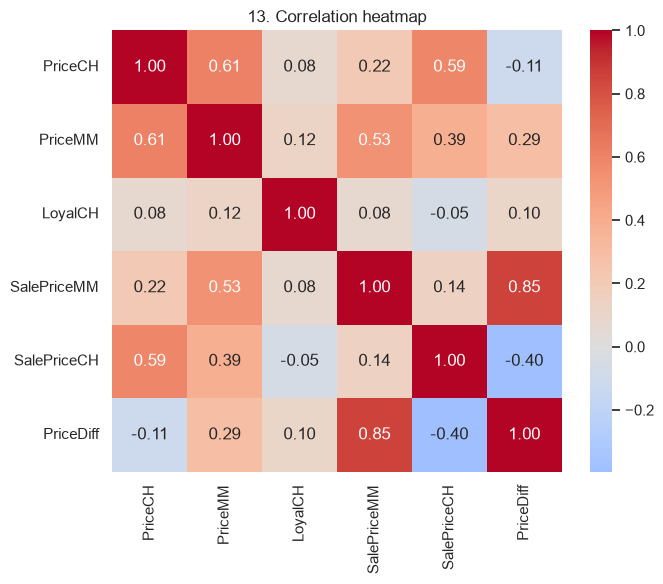

In [14]:
# 13. Correlation matrix + heatmap (>= 3 numeric variables)
corr = df[["PriceCH", "PriceMM", "LoyalCH", "SalePriceMM", "SalePriceCH", "PriceDiff"]].corr()
print("13. Correlation matrix:\n", corr.round(3), "\n")
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("13. Correlation heatmap")
plt.tight_layout(); plt.show()

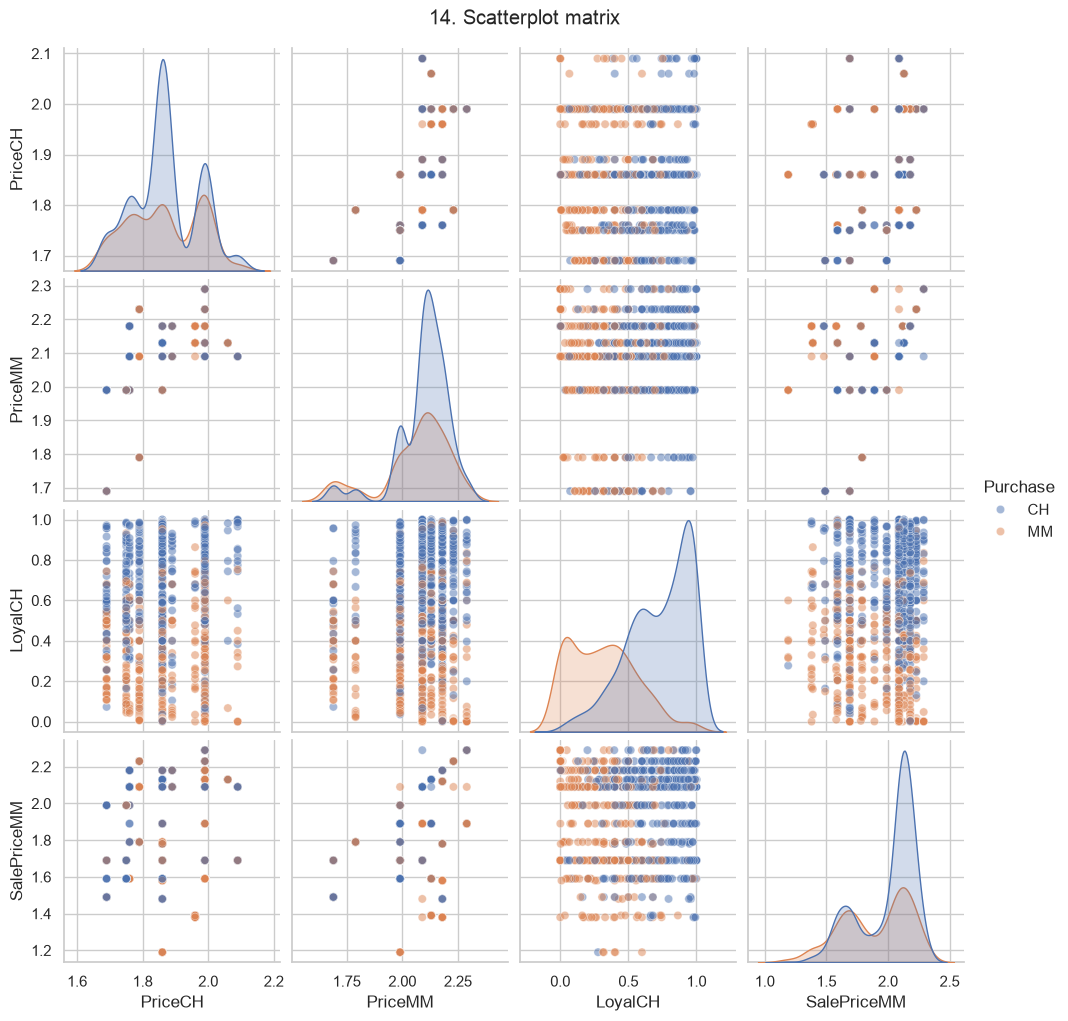

In [15]:
# 14. Pairs plot
g = sns.pairplot(df[["PriceCH", "PriceMM", "LoyalCH", "SalePriceMM", "Purchase"]], hue="Purchase",
                 plot_kws={"alpha": 0.5})
g.fig.suptitle("14. Scatterplot matrix", y=1.02)
plt.show()